# Subject-Specific Valence Learning Rates ($\alpha_{pos}, \alpha_{neg}$) & Variance Explained by GAD-7 (`06b`)

Whereas **Notebook 06** constrains between-subject variation in learning rates to be a purely deterministic function of GAD-7 (`alpha_i = invlogit(intercept + slope * GAD7_i)`), **this notebook (`06b`)** estimates **subject-specific** positive and negative learning rates by including hierarchical individual random effects ($z_i \cdot \sigma$) alongside the GAD-7 predictor:

$$\text{logit}(\alpha_{pos, i}) = \text{intercept}_{pos} + \text{slope}_{pos} \cdot \text{GAD7}_{\text{norm}, i} + z_{pos, i} \cdot \sigma_{pos}$$
$$\text{logit}(\alpha_{neg, i}) = \text{intercept}_{neg} + \text{slope}_{neg} \cdot \text{GAD7}_{\text{norm}, i} + z_{neg, i} \cdot \sigma_{neg}$$

### Key Outputs:
1. **Hierarchical GAD-7 Slopes (`slope_pos`, `slope_neg`):** Posterior distributions and 89% HDIs when accounting for between-subject random variance.
2. **Variance Explained ($R^2$) by GAD-7:**
   - **Bayesian Latent $R^2$ (logit scale):** $\frac{\text{Var}(\text{slope} \cdot \text{GAD7}_{\text{norm}})}{\text{Var}(\text{slope} \cdot \text{GAD7}_{\text{norm}}) + \sigma^2}$ across posterior draws.
   - **Subject-Level Empirical $R^2$:** Proportion of variance in the $N = 67$ subject-specific posterior mean learning rates ($\hat{\alpha}_{pos, i}$ and $\hat{\alpha}_{neg, i}$) explained by GAD-7.
3. **Subject-Specific $\hat{\alpha}_{pos, i}$ vs. $\hat{\alpha}_{neg, i}$ Correlation:** Tests how positive and negative learning rates co-vary across participants when each participant is free to deviate from the GAD-7 regression curve.


In [1]:
import pandas as pd
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
from scipy import stats
import warnings

from learning_functions import prepare_vectorized_bandit_data, step_m2_vec, get_hdi_bounds, plot_posterior_hdi

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


In [2]:
# Load Data and Vectorize across Subjects
file_path = '../data/allsubs_combined.csv'
df_raw = pd.read_csv(file_path).dropna(subset=['ChoiceKey', 'GAD7']).reset_index(drop=True).copy()

stim_map = {'W1': 0, 'W2': 1, 'L1': 2, 'L2': 3}
df_raw['LeftID_int'] = df_raw['LeftID'].map(stim_map)
df_raw['RightID_int'] = df_raw['RightID'].map(stim_map)
df_raw['ChosenID_int'] = df_raw['ChosenID'].map(stim_map)
df_raw['Choice'] = (df_raw['ChoiceKey'] - 1).astype(int)
df_raw['RewardScaled'] = df_raw['TrialPoints'] / 30.0

vdata = prepare_vectorized_bandit_data(df_raw)
df = vdata['df']
n_sub = vdata['n_sub']
unique_subs = vdata['unique_subs']

sub_gad7_map = df.groupby('SubIdx')['GAD7'].first()
gad7_scores = np.array([sub_gad7_map[i] for i in range(n_sub)])
gad7_normalized = gad7_scores / 21.0

print(f"Total subjects included: {n_sub}")
print(f"Total trials: {len(df)} (Vectorized scan length: {vdata['max_t']} steps)")


Total subjects included: 67
Total trials: 6520 (Vectorized scan length: 100 steps)


In [3]:
def build_hierarchical_gad7_valence_model(vdata, gad7_normalized):
    n_sub, t_idx, s_idx = vdata['n_sub'], vdata['t_idx'], vdata['s_idx']
    with pm.Model() as model:
        gad7_data = pm.Data("gad7_data", gad7_normalized)
        
        intercept_pos = pm.Normal('intercept_pos', mu=0, sigma=1.5)
        slope_pos = pm.Normal('slope_pos', mu=0, sigma=1.5)
        sigma_pos = pm.HalfNormal('sigma_pos', sigma=1.0)
        raw_pos = pm.Normal('raw_pos', mu=0, sigma=1, shape=n_sub)
        alpha_pos = pm.Deterministic('alpha_pos', pm.math.invlogit(intercept_pos + slope_pos * gad7_data + raw_pos * sigma_pos))
        
        intercept_neg = pm.Normal('intercept_neg', mu=0, sigma=1.5)
        slope_neg = pm.Normal('slope_neg', mu=0, sigma=1.5)
        sigma_neg = pm.HalfNormal('sigma_neg', sigma=1.0)
        raw_neg = pm.Normal('raw_neg', mu=0, sigma=1, shape=n_sub)
        alpha_neg = pm.Deterministic('alpha_neg', pm.math.invlogit(intercept_neg + slope_neg * gad7_data + raw_neg * sigma_neg))
        
        mu_beta_log = pm.Normal('mu_beta_log', mu=0, sigma=2.0)
        sigma_beta = pm.HalfNormal('sigma_beta', sigma=1.0)
        beta_raw = pm.Normal('beta_raw', mu=0, sigma=1, shape=n_sub)
        beta = pm.Deterministic('beta', pm.math.exp(mu_beta_log + beta_raw * sigma_beta))
        
        Q_init = pt.zeros((n_sub, 4))
        results = pytensor.scan(
            fn=step_m2_vec,
            sequences=[
                pt.as_tensor_variable(vdata['left_oh']),
                pt.as_tensor_variable(vdata['right_oh']),
                pt.as_tensor_variable(vdata['chosen_oh']),
                pt.as_tensor_variable(vdata['rew_mat']),
            ],
            outputs_info=[Q_init, None, None, None],
            non_sequences=[alpha_pos, alpha_neg],
            strict=True,
            return_updates=False
        )
        q_left_seq = results[1][t_idx, s_idx]
        q_right_seq = results[2][t_idx, s_idx]
        p_right_raw = pm.math.sigmoid(beta[s_idx] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        pm.Bernoulli('choice_obs', p=p_right, observed=vdata['df']['Choice'].values)
    return model

print("Building vectorized hierarchical subject-specific GAD-7 model...")
m_hier_gad7 = build_hierarchical_gad7_valence_model(vdata, gad7_normalized)


Building vectorized hierarchical subject-specific GAD-7 model...


In [4]:
print("Sampling posterior using nutpie (PyMC 6)...")
with m_hier_gad7:
    idata = pm.sample(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=True)
print("Sampling complete!")


Sampling posterior using nutpie (PyMC 6)...


NUTS[nutpie]: [intercept_pos, slope_pos, sigma_pos, raw_pos, intercept_neg, slope_neg, sigma_neg, raw_neg, mu_beta_log, sigma_beta, beta_raw]


Output()

Sampling complete!


In [5]:
# 1. Extract Slopes, Random Effect SDs, and Compute Explained Variance (R^2)
sp_low, sp_high = get_hdi_bounds(idata, 'slope_pos', prob=0.89)
sn_low, sn_high = get_hdi_bounds(idata, 'slope_neg', prob=0.89)
sigp_low, sigp_high = get_hdi_bounds(idata, 'sigma_pos', prob=0.89)
sign_low, sign_high = get_hdi_bounds(idata, 'sigma_neg', prob=0.89)

slope_pos_draws = idata.posterior['slope_pos'].values.flatten()
slope_neg_draws = idata.posterior['slope_neg'].values.flatten()
sigma_pos_draws = idata.posterior['sigma_pos'].values.flatten()
sigma_neg_draws = idata.posterior['sigma_neg'].values.flatten()

# Latent Bayesian R^2 on logit scale: Var(slope * gad7_norm) / (Var(slope * gad7_norm) + sigma^2)
var_gad7_norm = np.var(gad7_normalized, ddof=1)
var_explained_pos_draws = (slope_pos_draws ** 2) * var_gad7_norm
r2_latent_pos_draws = var_explained_pos_draws / (var_explained_pos_draws + sigma_pos_draws ** 2)

var_explained_neg_draws = (slope_neg_draws ** 2) * var_gad7_norm
r2_latent_neg_draws = var_explained_neg_draws / (var_explained_neg_draws + sigma_neg_draws ** 2)

r2_pos_hdi = np.quantile(r2_latent_pos_draws, [0.055, 0.945])
r2_neg_hdi = np.quantile(r2_latent_neg_draws, [0.055, 0.945])

# Subject-specific posterior means
alpha_pos_samples = idata.posterior['alpha_pos'].values.reshape(-1, n_sub)
alpha_neg_samples = idata.posterior['alpha_neg'].values.reshape(-1, n_sub)
beta_samples = idata.posterior['beta'].values.reshape(-1, n_sub)

alpha_pos_mean = alpha_pos_samples.mean(axis=0)
alpha_neg_mean = alpha_neg_samples.mean(axis=0)
beta_mean = beta_samples.mean(axis=0)

# Save subject-specific parameters to CSV
df_sub_params = pd.DataFrame({
    'Sub': unique_subs,
    'GAD7': gad7_scores,
    'alpha_pos': alpha_pos_mean,
    'alpha_neg': alpha_neg_mean,
    'beta': beta_mean
})
df_sub_params.to_csv('../data/rl_valence_subject_parameters.csv', index=False)

# Empirical R^2 between subject posterior means and GAD-7
r_pos_gad, p_pos_gad = stats.pearsonr(gad7_scores, alpha_pos_mean)
r_neg_gad, p_neg_gad = stats.pearsonr(gad7_scores, alpha_neg_mean)

# Subject-level correlation between alpha_pos and alpha_neg
r_pos_neg, p_pos_neg = stats.pearsonr(alpha_pos_mean, alpha_neg_mean)
rho_pos_neg, prho_pos_neg = stats.spearmanr(alpha_pos_mean, alpha_neg_mean)

print("==========================================================================")
print("HIERARCHICAL SUBJECT-SPECIFIC VALENCE + GAD-7 RESULTS (89% HDI)")
print("==========================================================================")


print(f"Slope Positive (alpha_pos): Mean = {slope_pos_draws.mean():+.3f} | 89% HDI [{sp_low:+.3f}, {sp_high:+.3f}]")
print(f"Sigma Positive (random SD): Mean = {sigma_pos_draws.mean():.3f} | 89% HDI [{sigp_low:.3f}, {sigp_high:.3f}]")
print(f"Slope Negative (alpha_neg): Mean = {slope_neg_draws.mean():+.3f} | 89% HDI [{sn_low:+.3f}, {sn_high:+.3f}]")
print(f"Sigma Negative (random SD): Mean = {sigma_neg_draws.mean():.3f} | 89% HDI [{sign_low:.3f}, {sign_high:.3f}]")

print("\n--------------------------------------------------------------------------")
print("VARIANCE EXPLAINED (R^2) BY GAD-7")
print("--------------------------------------------------------------------------")
print(f"1. Latent Hierarchical R^2 (logit scale, across posterior draws):")
print(f"   alpha_pos R^2: Mean = {r2_latent_pos_draws.mean()*100:.2f}% (Median = {np.median(r2_latent_pos_draws)*100:.2f}%) | 89% HDI [{r2_pos_hdi[0]*100:.2f}%, {r2_pos_hdi[1]*100:.2f}%]")
print(f"   alpha_neg R^2: Mean = {r2_latent_neg_draws.mean()*100:.2f}% (Median = {np.median(r2_latent_neg_draws)*100:.2f}%) | 89% HDI [{r2_neg_hdi[0]*100:.2f}%, {r2_neg_hdi[1]*100:.2f}%]")

print(f"\n2. Subject-Level Posterior Mean R^2 (N = {n_sub} subject estimates vs. GAD-7):")
print(f"   alpha_pos vs. GAD-7: r = {r_pos_gad:+.4f}, R^2 = {(r_pos_gad**2)*100:.2f}% (p = {p_pos_gad:.4f})")
print(f"   alpha_neg vs. GAD-7: r = {r_neg_gad:+.4f}, R^2 = {(r_neg_gad**2)*100:.2f}% (p = {p_neg_gad:.4f})")

print("\n--------------------------------------------------------------------------")
print(f"SUBJECT-SPECIFIC CORRELATION: alpha_pos vs. alpha_neg (N = {n_sub})")
print("--------------------------------------------------------------------------")
print(f"   Pearson r  = {r_pos_neg:+.4f} (p = {p_pos_neg:.4f})")
print(f"   Spearman r = {rho_pos_neg:+.4f} (p = {prho_pos_neg:.4f})")
print("==========================================================================\n")


HIERARCHICAL SUBJECT-SPECIFIC VALENCE + GAD-7 RESULTS (89% HDI)
Slope Positive (alpha_pos): Mean = +0.495 | 89% HDI [-1.034, +2.049]
Sigma Positive (random SD): Mean = 1.436 | 89% HDI [0.959, 1.884]
Slope Negative (alpha_neg): Mean = +0.157 | 89% HDI [-1.440, +1.823]
Sigma Negative (random SD): Mean = 1.828 | 89% HDI [1.422, 2.264]

--------------------------------------------------------------------------
VARIANCE EXPLAINED (R^2) BY GAD-7
--------------------------------------------------------------------------
1. Latent Hierarchical R^2 (logit scale, across posterior draws):
   alpha_pos R^2: Mean = 2.81% (Median = 1.17%) | 89% HDI [0.01%, 10.95%]
   alpha_neg R^2: Mean = 1.52% (Median = 0.71%) | 89% HDI [0.01%, 5.46%]

2. Subject-Level Posterior Mean R^2 (N = 67 subject estimates vs. GAD-7):
   alpha_pos vs. GAD-7: r = +0.1508, R^2 = 2.28% (p = 0.2230)
   alpha_neg vs. GAD-7: r = +0.0200, R^2 = 0.04% (p = 0.8723)

--------------------------------------------------------------------

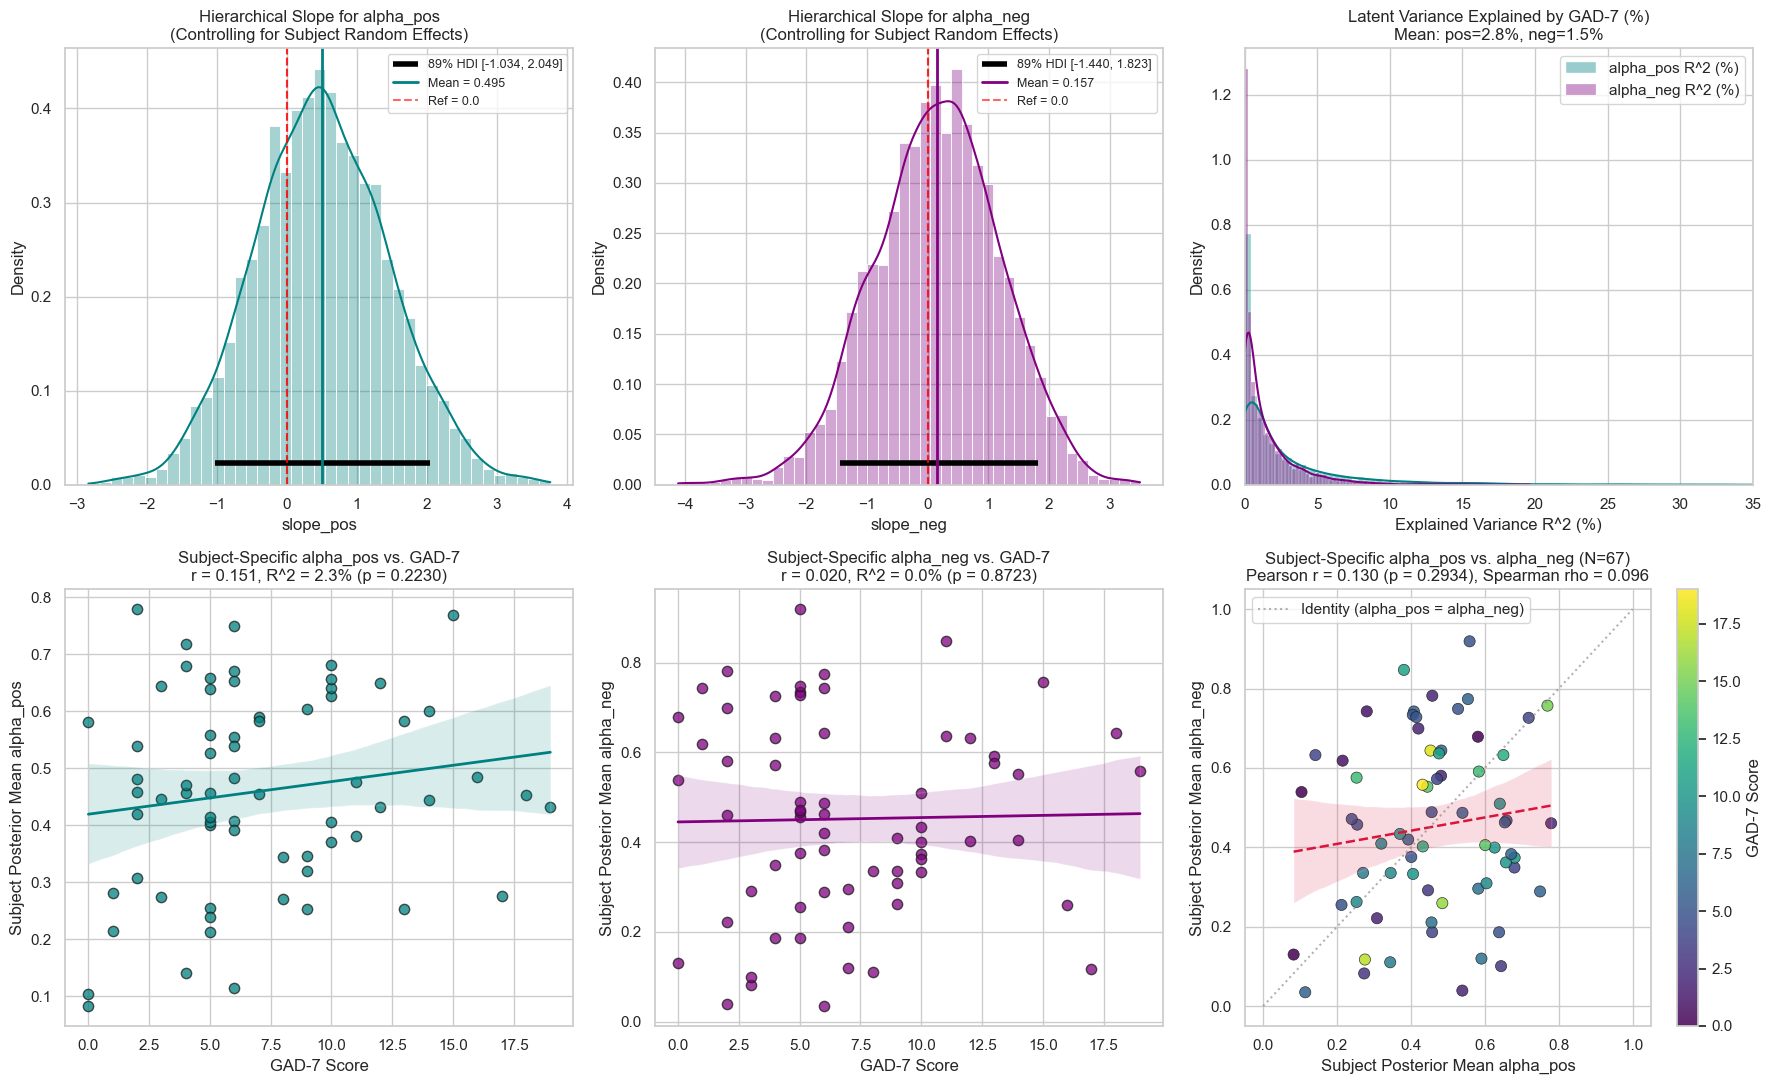

In [6]:
# Plot Posterior Slopes & Subject-Specific Learning Rate Relationships
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# Row 1, Col 1: Posterior of slope_pos
plot_posterior_hdi(idata, "slope_pos", prob=0.89, ax=axes[0, 0], color="teal")
axes[0, 0].set_title("Hierarchical Slope for alpha_pos\n(Controlling for Subject Random Effects)")
axes[0, 0].axvline(0, color='red', linestyle='--', alpha=0.6)

# Row 1, Col 2: Posterior of slope_neg
plot_posterior_hdi(idata, "slope_neg", prob=0.89, ax=axes[0, 1], color="purple")
axes[0, 1].set_title("Hierarchical Slope for alpha_neg\n(Controlling for Subject Random Effects)")
axes[0, 1].axvline(0, color='red', linestyle='--', alpha=0.6)

# Row 1, Col 3: Posterior distribution of Latent R^2
sns.histplot(r2_latent_pos_draws * 100, kde=True, stat="density", color="teal", alpha=0.4, label="alpha_pos R^2 (%)", ax=axes[0, 2])
sns.histplot(r2_latent_neg_draws * 100, kde=True, stat="density", color="purple", alpha=0.4, label="alpha_neg R^2 (%)", ax=axes[0, 2])
axes[0, 2].set_title(f"Latent Variance Explained by GAD-7 (%)\nMean: pos={r2_latent_pos_draws.mean()*100:.1f}%, neg={r2_latent_neg_draws.mean()*100:.1f}%")
axes[0, 2].set_xlabel("Explained Variance R^2 (%)")
axes[0, 2].set_xlim(0, max(35, np.percentile(r2_latent_pos_draws * 100, 99)))
axes[0, 2].legend()

# Row 2, Col 1: Subject-specific alpha_pos vs GAD-7
sns.regplot(x=gad7_scores, y=alpha_pos_mean, ax=axes[1, 0], color="teal",
            scatter_kws={'alpha': 0.75, 's': 55, 'edgecolor': 'k'}, line_kws={'linewidth': 2})
axes[1, 0].set_title(f"Subject-Specific alpha_pos vs. GAD-7\nr = {r_pos_gad:.3f}, R^2 = {(r_pos_gad**2)*100:.1f}% (p = {p_pos_gad:.4f})")
axes[1, 0].set_xlabel("GAD-7 Score")
axes[1, 0].set_ylabel("Subject Posterior Mean alpha_pos")

# Row 2, Col 2: Subject-specific alpha_neg vs GAD-7
sns.regplot(x=gad7_scores, y=alpha_neg_mean, ax=axes[1, 1], color="purple",
            scatter_kws={'alpha': 0.75, 's': 55, 'edgecolor': 'k'}, line_kws={'linewidth': 2})
axes[1, 1].set_title(f"Subject-Specific alpha_neg vs. GAD-7\nr = {r_neg_gad:.3f}, R^2 = {(r_neg_gad**2)*100:.1f}% (p = {p_neg_gad:.4f})")
axes[1, 1].set_xlabel("GAD-7 Score")
axes[1, 1].set_ylabel("Subject Posterior Mean alpha_neg")

# Row 2, Col 3: Subject-specific alpha_pos vs alpha_neg colored by GAD-7
sc = axes[1, 2].scatter(alpha_pos_mean, alpha_neg_mean, c=gad7_scores, cmap='viridis', s=65, alpha=0.85, edgecolors='k', linewidth=0.5)
sns.regplot(x=alpha_pos_mean, y=alpha_neg_mean, ax=axes[1, 2], scatter=False, color='crimson', line_kws={'linestyle': '--', 'linewidth': 1.8})
axes[1, 2].plot([0, 1], [0, 1], color='gray', linestyle=':', alpha=0.6, label='Identity (alpha_pos = alpha_neg)')
cbar = plt.colorbar(sc, ax=axes[1, 2])
cbar.set_label('GAD-7 Score')
axes[1, 2].set_title(f"Subject-Specific alpha_pos vs. alpha_neg (N={n_sub})\nPearson r = {r_pos_neg:.3f} (p = {p_pos_neg:.4f}), Spearman rho = {rho_pos_neg:.3f}")
axes[1, 2].set_xlabel("Subject Posterior Mean alpha_pos")
axes[1, 2].set_ylabel("Subject Posterior Mean alpha_neg")
axes[1, 2].legend(loc='upper left')

plt.tight_layout()
plt.savefig('../data/alpha_pos_vs_alpha_neg_nb06b.png', dpi=150, bbox_inches='tight')
plt.show()
